# GP-A and GP-B: longitudinal physiology

Both models use a multi-output GP to represent continuous physiological trajectories, including covariance between BP, glucose and creatinine. **The modelling choice is which space has a Gaussian observation distribution.**

For **GP-A**, the latent trajectory is observed with additive Gaussian measurement noise:

\[
y=f+\epsilon_G.
\]

Consequently, observations and predictions are Gaussian in the model's standardised clinical feature space. This gives a simple baseline with symmetric predictive intervals; learning a nonlinear kernel changes the covariance, but does not make the observation distribution non-Gaussian.

For **GP-B**, we first form the same noisy Gaussian quantity, then pass it through a learned invertible observation transformation:

\[
g=f+\epsilon_G,\qquad y=T_\psi(g).
\]

Here the Gaussian assumption holds in the transformed latent space. In clinical units, predictions can be skewed and have different tail shapes. The transformation acts on the **noisy observation**, rather than only the noise-free trajectory. Invertibility lets us map observed values back to Gaussian space and evaluate an exact likelihood with a Jacobian correction.

Thus GP-A chooses a Gaussian observation model; GP-B adds flexibility in the observed distribution at the cost of learning an additional transformation. Both retain temporal and cross-feature dependence through the GP. We use the same irregular clinical measurements throughout; no regular grid is created for training.

**Clinical input encoding used throughout these models.** Categories use small learned embeddings: sex, employment, record kind and event type use two coordinates; marital status and history-variable identity use three, while GP query-output identity uses two. Missing/unseen categories are explicit. A category that does not apply to a token uses a zero padding embedding. Adapter indicators are decoded to IDs before neural computation. Physiological values remain training-standardised, with explicit missingness and known-value flags. With small vocabularies, embeddings provide a compact representation; a one-hot vector followed by a linear projection already learns category vectors, so this change does not automatically improve predictions.

Age supplies a **learned continuous absolute-age encoding**, rather than a raw content feature or a sinusoidal code. A small two-layer network maps age in years into the model's hidden dimension:

\[
\mathrm{PE}_\omega(a)=W_2\tanh\!\left(W_1\frac{a}{100}+b_1\right)+b_2.
\]

History tokens add this encoding after their learned content projection. TPP-A reconstructs record ages from entry age and accumulated IATs; dynamic TPPs and GP histories use recorded ages. Equal-age records share an encoding, while the causal attention mask still prevents attending to later records. Each conditioning network replaces age scalars with learned age encodings and categorical indicators with embeddings. All encoding parameters are trained with the model. Duration/IAT inputs retain their log scaling.

The GP still uses actual age differences as its continuous covariance coordinate; output IDs select the covariance matrix. Its neural mean, feature maps and flows receive learned age and output embeddings. This removes imposed periodicity, but does not guarantee reliable extrapolation or a biologically correct ageing trajectory.

In [1]:
from pathlib import Path
import torch
import sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path: sys.path.insert(0, str(ROOT))
plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False})
from lifetime_clinical.tutorials.experiments import load_toy,gp_data,fit_gp_a,fit_gp_b,representative_gp_block
from lifetime_clinical.visualization import plot_fit_history,plot_gp_feature,plot_sampled_predictive_density
from lifetime_clinical.data.preprocessing import VARIABLES

In [2]:
FAST_MODE=True
EPOCHS=5 if FAST_MODE else 10
DEVICE="cuda" if torch.cuda.is_available() else "cpu"
DATA_DIR=ROOT/"data"/("toy" if FAST_MODE else "synthetic")
dataset,splits,pre=load_toy(DATA_DIR)
print("device",DEVICE,"epochs",EPOCHS,"dataset",DATA_DIR)
blocks=gp_data(dataset,splits,pre,history_fraction=.25)
conditioning,heldout=representative_gp_block(blocks["test"],min_panels=5)
print("patient",conditioning.patient_id,"conditioning rows",len(conditioning.y),"held-out rows",len(heldout.y))
print("measurement blocks",{name:len(values) for name,values in blocks.items()})

device cpu epochs 5 dataset C:\Users\dario\Desktop\Doctorado\lifetime_clinical_tutorial\data\toy


patient P001201 conditioning rows 18 held-out rows 12
measurement blocks {'train': 97, 'validation': 20, 'test': 10}


## GP-A — deep-kernel Gaussian GP

The latent physiology is

\[
f\sim GP(m,k_\theta).
\]

Rather than let an unconstrained MLP output a kernel value directly, we first learn a representation

\[
r_{td}=\phi_\theta(\operatorname{Emb}(s),H,\mathrm{PE}(t),\operatorname{Emb}(d)),
\]

Here \(\phi_\theta\) is a learned neural feature map with parameters \(\theta\): it maps the patient/history context \(H\), query-age positional code \(\mathrm{PE}(t)\), baseline embeddings, and learned feature identity embedding \(\operatorname{Emb}(d)\) into an \(R\)-dimensional vector \(r_{td}\). The index \(d\) identifies BP, glucose or creatinine. This \(\phi_\theta\) is a neural network, not the standard normal density \(\phi\) used in the flow formulas.

We then build a guaranteed positive-semidefinite kernel from inner products and a PSD coregionalisation term, schematically

\[
k((t,d),(t',d'))
=\frac{\phi_\theta(q)^\top\phi_\theta(q')}{R}
+k_{time}(t,t')\,[BB^\top]_{dd'}.
\]

Here \(q=(\operatorname{Emb}(s),H,\mathrm{PE}(t),\operatorname{Emb}(d))\) denotes the complete query input, \(R\) is the representation dimension, and \(B\) is a learned matrix whose product \(BB^\top\) represents cross-feature covariance.

With Gaussian noise,

\[
y=f+\epsilon_G,\qquad \epsilon_G\sim\mathcal N(0,\Sigma),
\]

the marginal likelihood is exact.  
**Learns:** a joint continuous-time distribution over BP, glucose and creatinine.

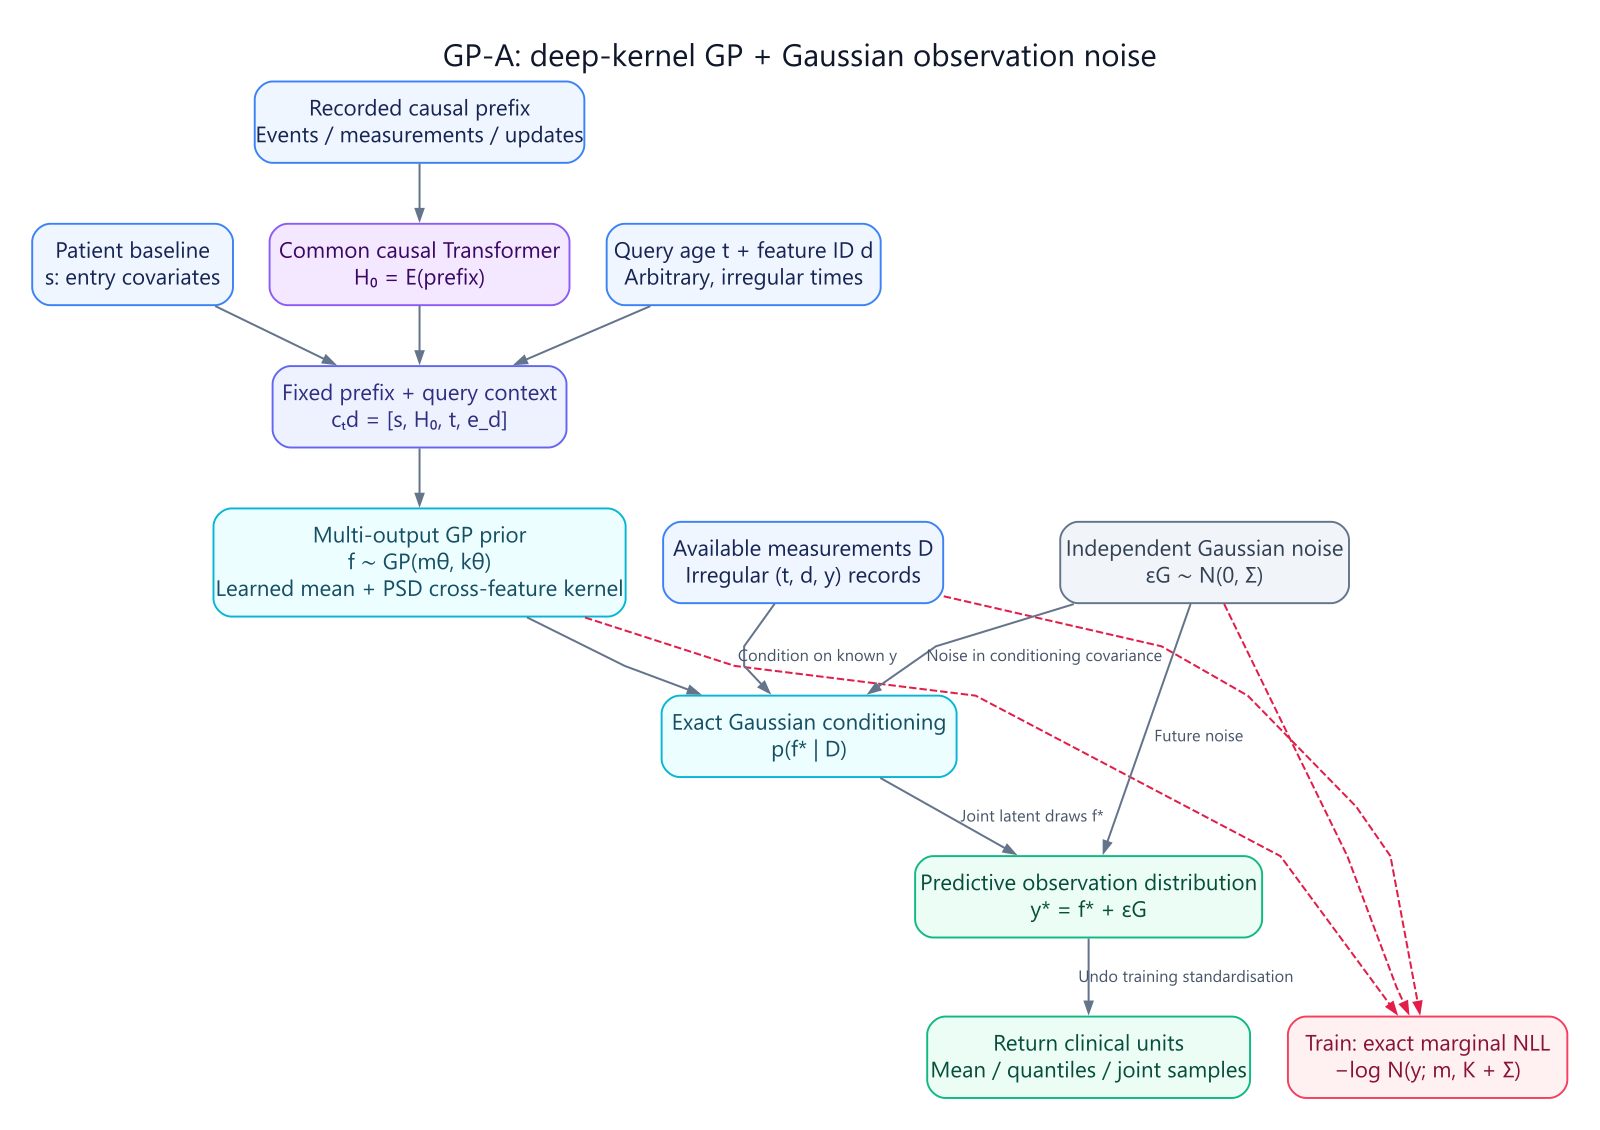

In [3]:
from IPython.display import display
import base64
# GP-A: inputs → outputs
display({
    'image/svg+xml': (ROOT / 'diagrams/gp_a.svg').read_text(encoding='utf-8'),
    'image/png': base64.b64encode((ROOT / 'diagrams/gp_a.png').read_bytes()).decode('ascii'),
}, raw=True)

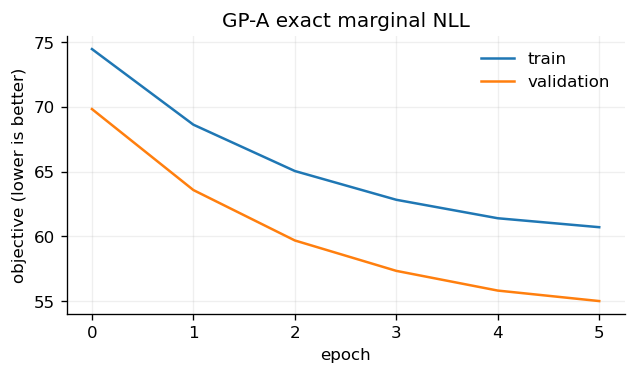

In [4]:
gp_a=fit_gp_a(blocks,epochs=EPOCHS,device=DEVICE)
fig,ax=plt.subplots(figsize=(6,3)); plot_fit_history(gp_a,ax,title="GP-A exact marginal NLL"); plt.show()

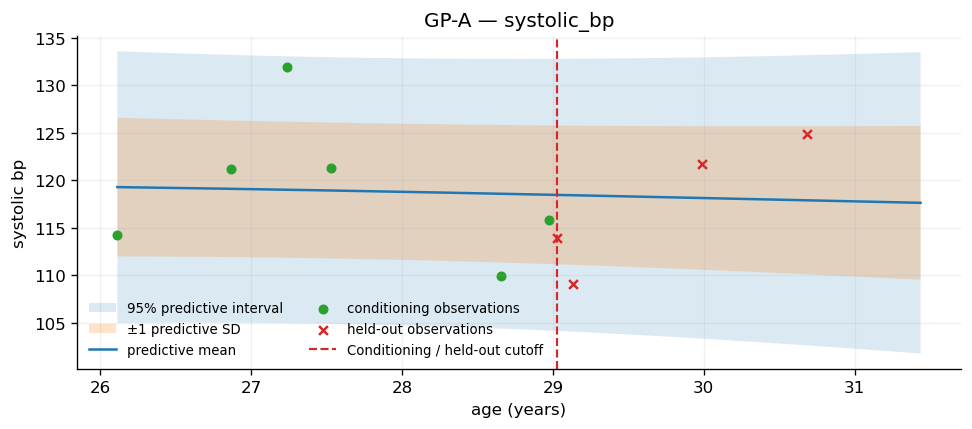

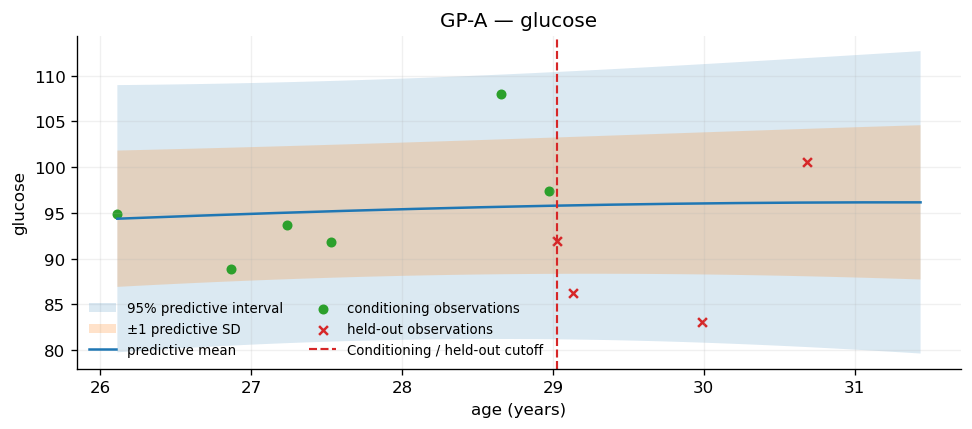

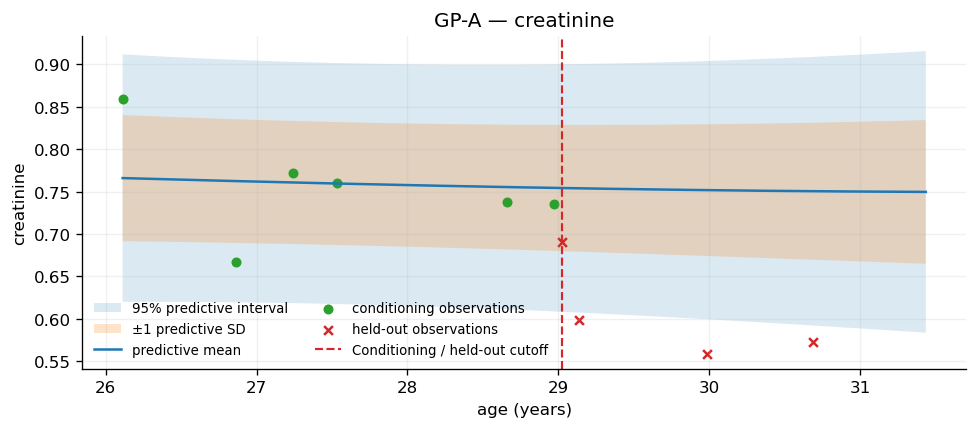

In [5]:
cutoff_age = float(heldout.ages.min())*100
lo=min(conditioning.ages.min(),heldout.ages.min())*100
hi=max(conditioning.ages.max(),heldout.ages.max())*100+.75
age_grid=np.linspace(lo,hi,180)
for vid,v in enumerate(VARIABLES):
    fig,ax=plt.subplots(figsize=(9.5,3.6))
    plot_gp_feature(gp_a,conditioning,heldout,vid,age_grid,ax=ax)
    ax.axvline(cutoff_age, color="tab:red", linestyle="--", linewidth=1.3,
               label="Conditioning / held-out cutoff")
    ax.legend(frameon=False,ncol=2,fontsize=8)
    plt.show()

These are the usual GP plots, one **individual feature at a time**. The model is still multi-output: a creatinine measurement can influence BP inference through learned cross-output covariance, even though we display each marginal trajectory separately.

## GP-B — transformed-observation GP

Let

\[
g=f+\epsilon_G,\qquad g\sim\mathcal N(m,K+\Sigma),
\]

then apply an invertible observation flow

\[
y=T_\psi(g).
\]

For an observed \(y\),

\[
\log p(y)=\log\mathcal N(T^{-1}(y);m,K+\Sigma)
+\log|\det J_{T^{-1}}(y)|.
\]

So GP-B retains an exact change-of-variable likelihood but its observed predictive distribution need not be Gaussian. It is therefore better visualised by sampling the predictive distribution than by blindly drawing \(\mu\pm2\sigma\).

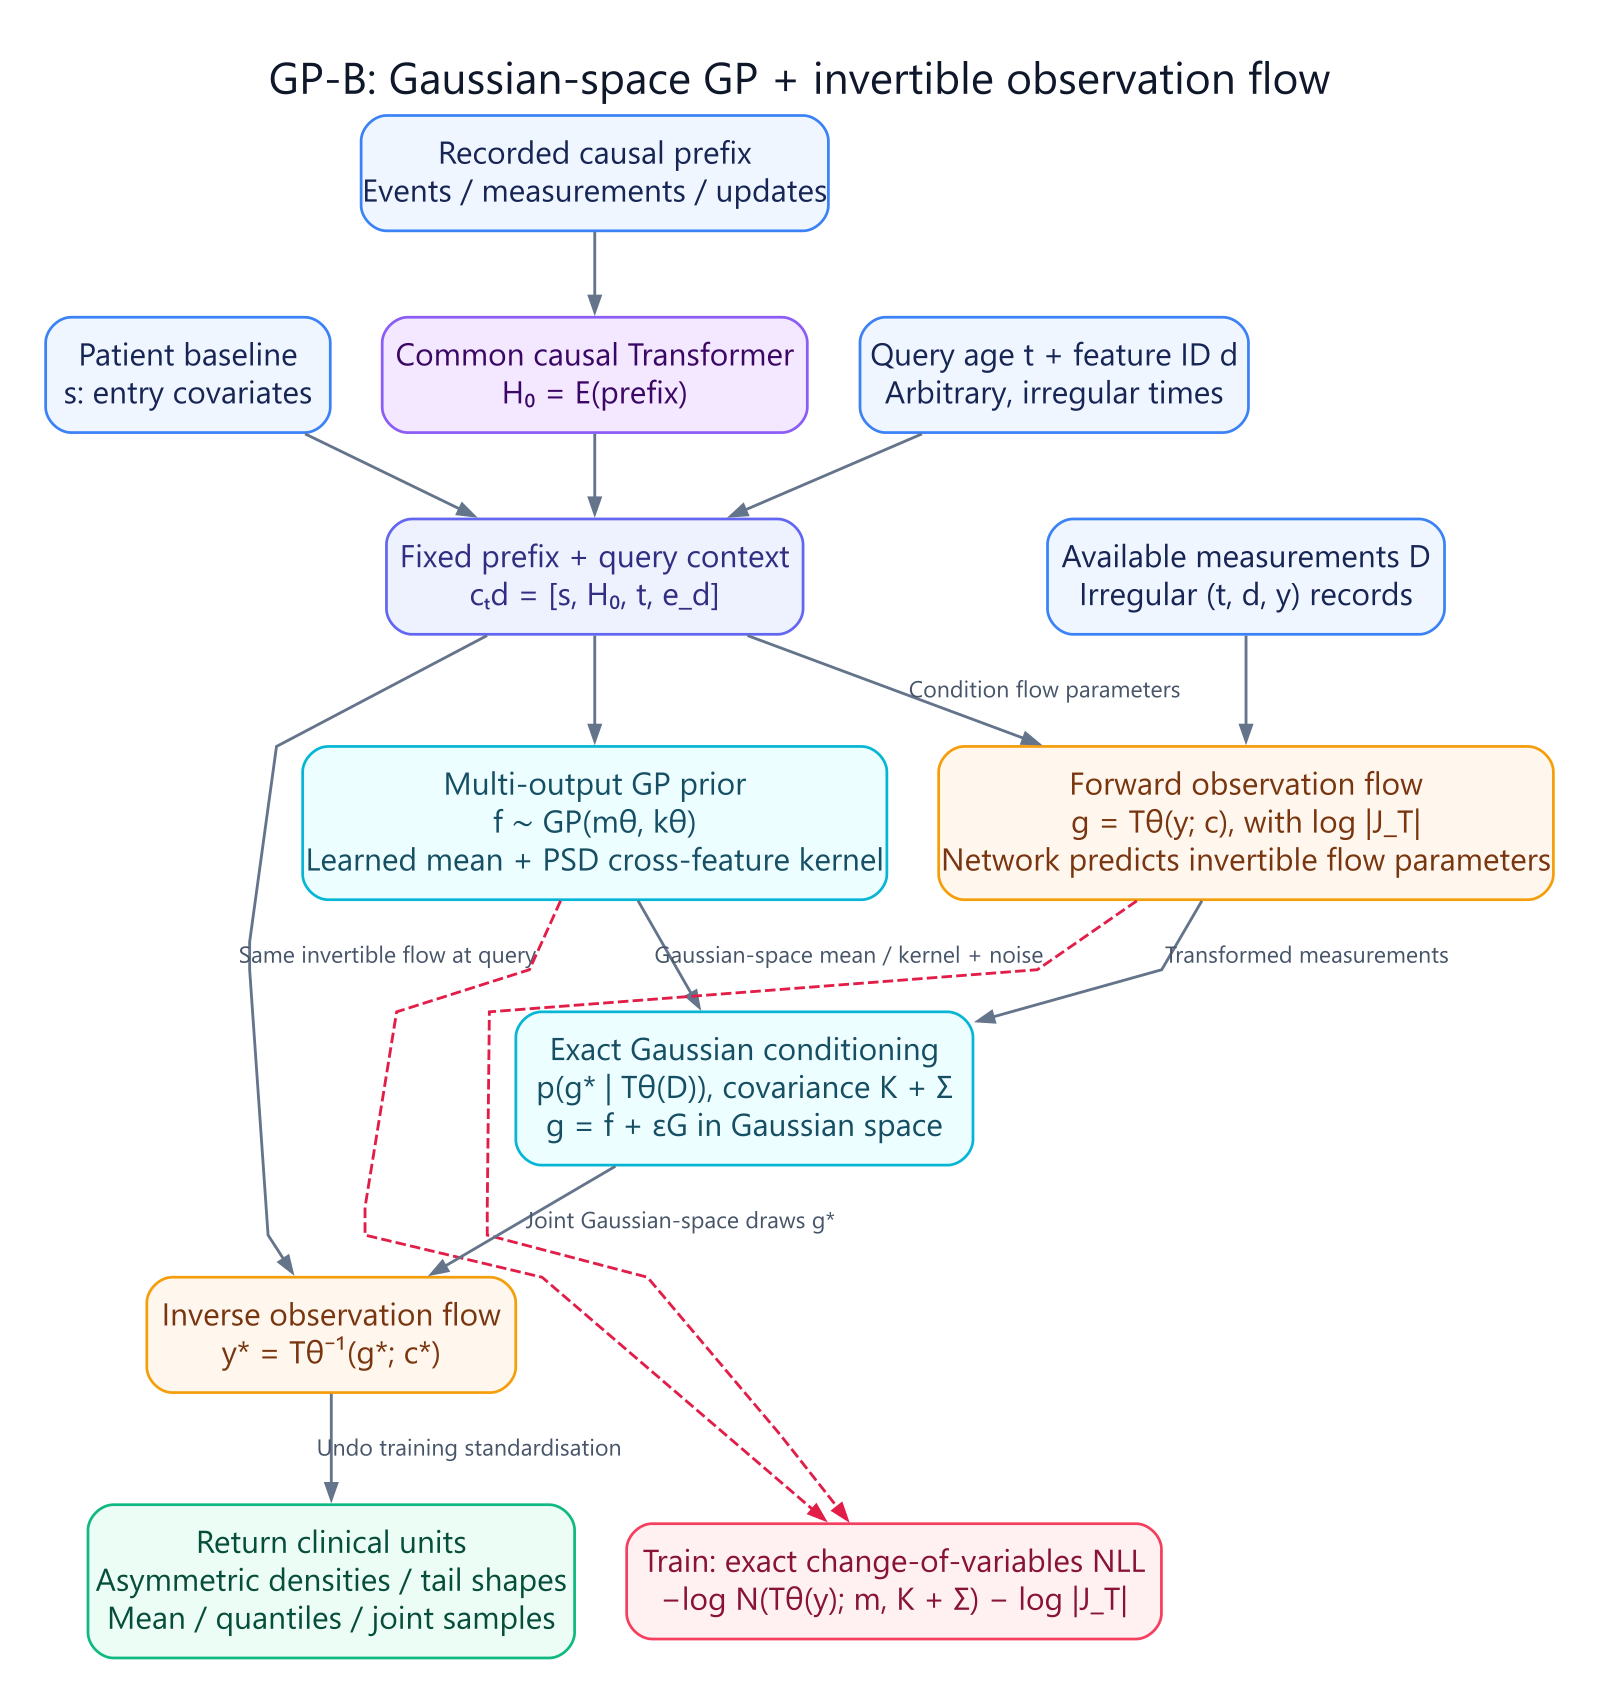

In [6]:
from IPython.display import display
import base64
# GP-B: inputs → outputs
display({
    'image/svg+xml': (ROOT / 'diagrams/gp_b.svg').read_text(encoding='utf-8'),
    'image/png': base64.b64encode((ROOT / 'diagrams/gp_b.png').read_bytes()).decode('ascii'),
}, raw=True)

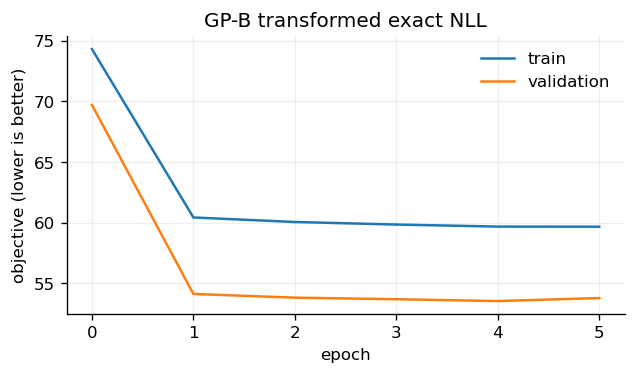

In [7]:
gp_b=fit_gp_b(blocks,epochs=EPOCHS,device=DEVICE)
fig,ax=plt.subplots(figsize=(6,3)); plot_fit_history(gp_b,ax,title="GP-B transformed exact NLL"); plt.show()

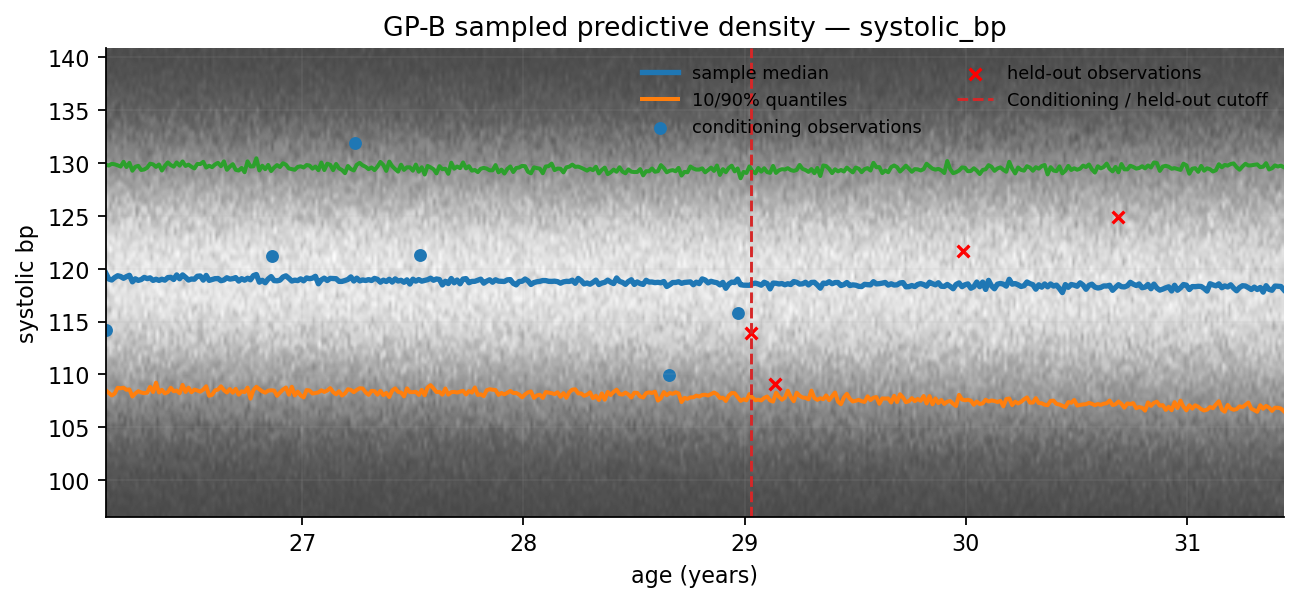

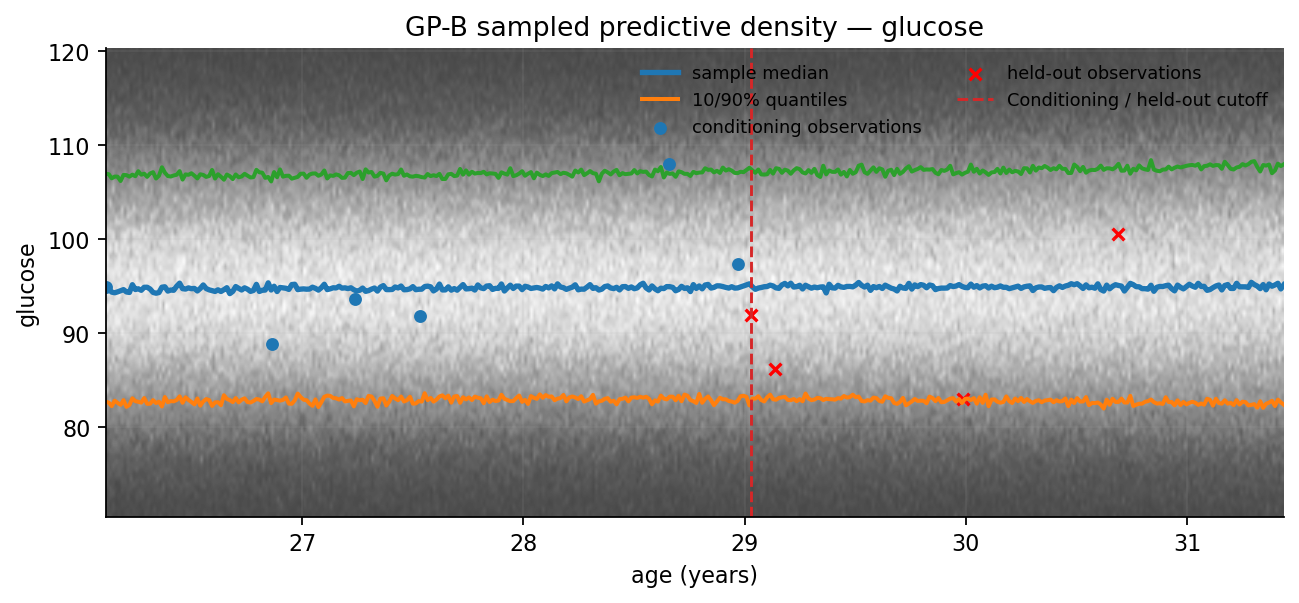

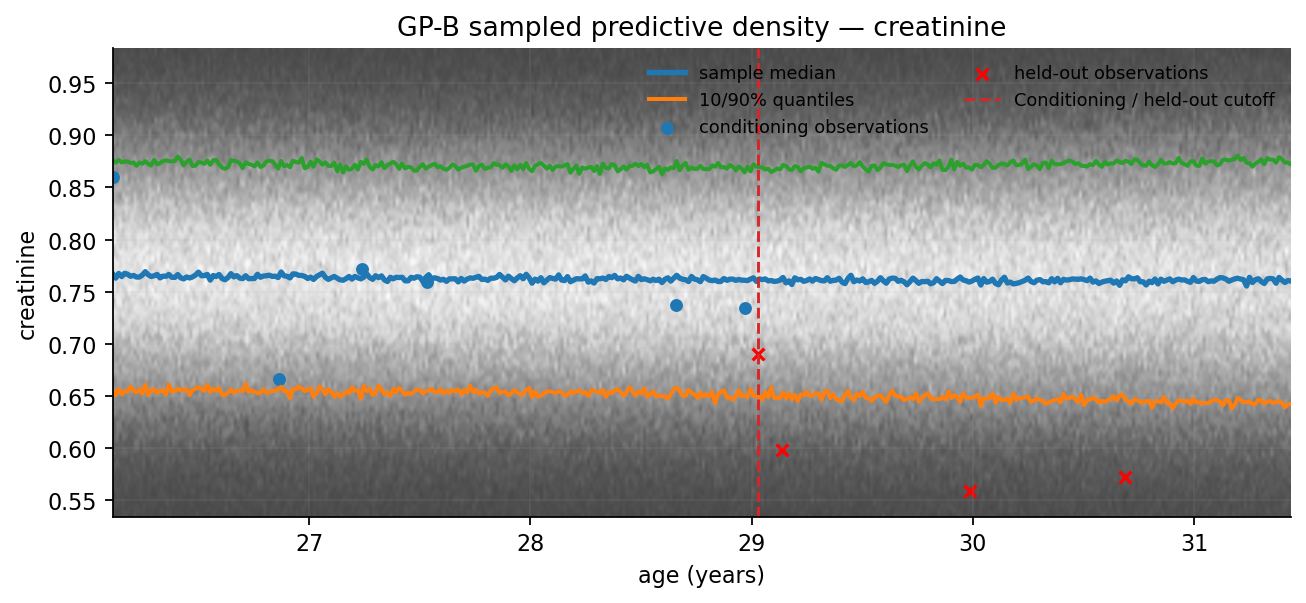

In [8]:
density_age_grid=np.linspace(lo,hi,400)
for vid,v in enumerate(VARIABLES):
    fig,ax=plt.subplots(figsize=(9.5,3.8),dpi=160)
    plot_sampled_predictive_density(gp_b,conditioning,heldout,vid,density_age_grid,
                                    ax=ax,n_samples=3000,bins=220,cmap="Greys_r",seed=20+vid,
                                    title=f"GP-B sampled predictive density — {v}")
    # Style the held-out observations independently of the density curves.
    for collection in ax.collections:
        if collection.get_label() == "held-out observations":
            collection.set_color("red")
    ax.axvline(cutoff_age,color="tab:red",linestyle="--",linewidth=1.3,
               label="Conditioning / held-out cutoff")
    ax.legend(frameon=False,ncol=2,fontsize=8)
    plt.show()

The heatmap is **visualisation only**: samples come from the fitted GP-B predictive distribution. No KDE or histogram approximation is used in the training objective.

GP-A and GP-B both answer the same clinical query for each feature:

\[
p(y_d(t_*)\mid\text{observed history}),
\]

but GP-B allows a more flexible observed marginal shape.

## Comparing GP-A and GP-B by NLL

Here the NLLs **are comparable**: both models assign density to the same test patients' multivariate measurement blocks, at the same irregular times, using the same preprocessing and clinical units. GP-B includes its inverse-transformation Jacobian; both include the standardisation Jacobian. Thus both scores refer to observed measurements, even though GP-B uses a different latent observation space.

The table reports exact block marginal NLL averaged per patient block (nats/block). Lower is better for this common target. This is a test-block likelihood comparison, not the conditional held-out forecast NLL from the dashed cutoff in the plots. Continuous-density NLLs depend on units and can be negative; compare these models within this table, not against TPP scores or different target sets. With ten training epochs in full-data mode (five in fast mode), the result remains illustrative rather than a definitive ranking.

In [9]:
gp_nll_comparison = pd.DataFrame([
    {"Model": name, "Test marginal NLL (nats/block)": model.score(blocks["test"])}
    for name, model in [("GP-A", gp_a), ("GP-B", gp_b)]
]).set_index("Model")
display(gp_nll_comparison)


,Test marginal NLL (nats/block)
Model,
GP-A,64.383018
GP-B,63.295571


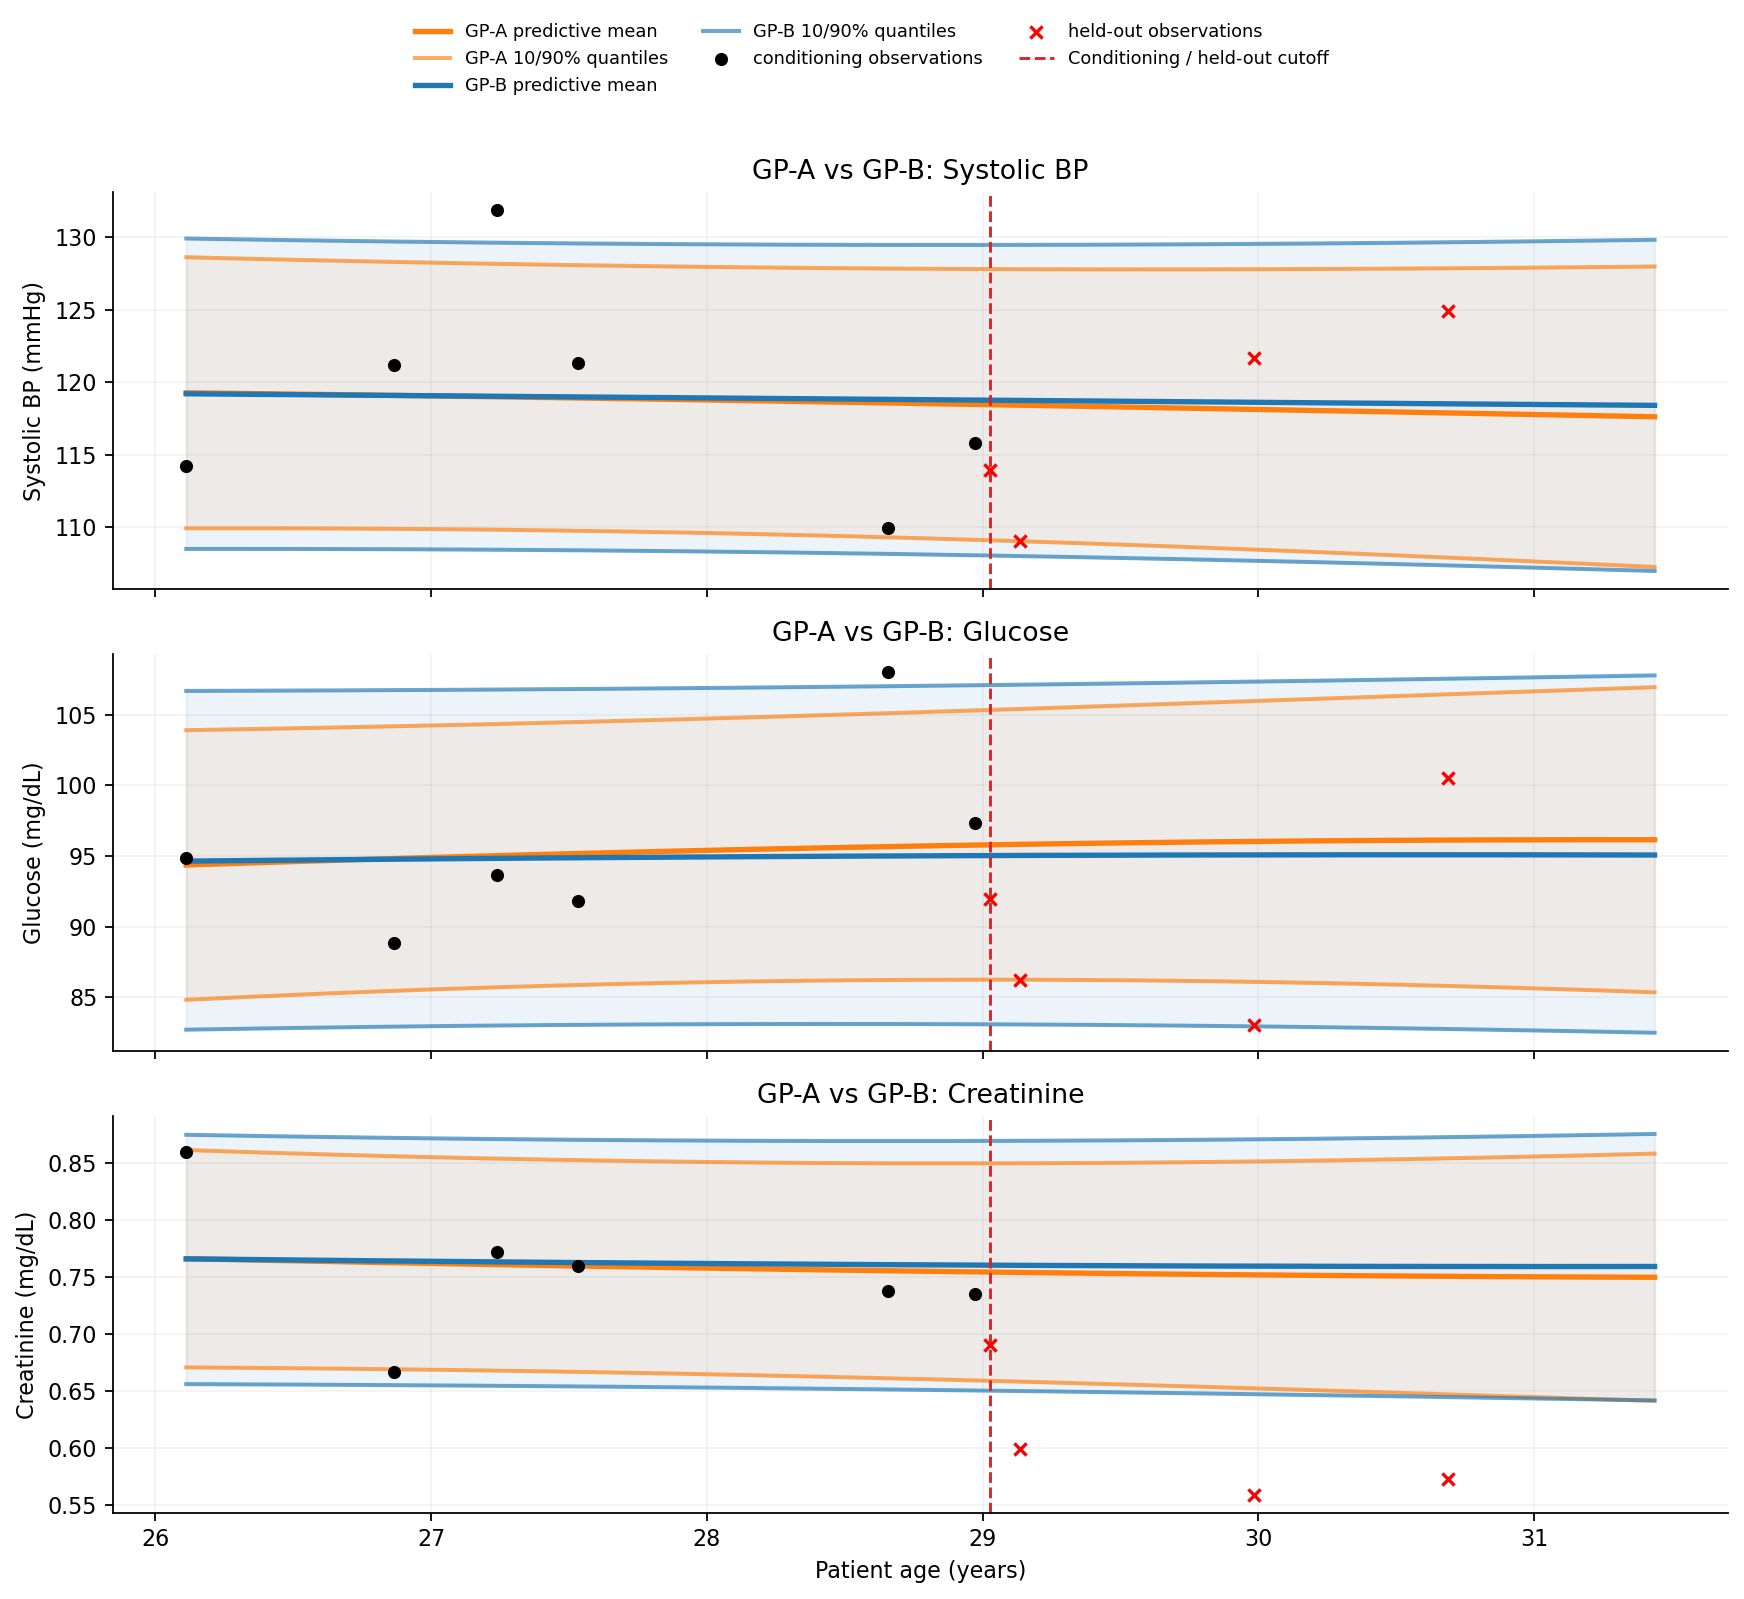

In [10]:
# Compare observation predictions using the same history and query times.
# Solid means and lighter solid 10/90% quantiles include measurement noise.
comparison_age_grid=np.linspace(lo,hi,400)
fig,axes=plt.subplots(3,1,figsize=(11,10),sharex=True,dpi=160)
for vid,(ax,v) in enumerate(zip(axes,VARIABLES)):
    ids=np.full(len(comparison_age_grid),vid,dtype=int)
    for name,model,colour in [("GP-A",gp_a,"tab:orange"),("GP-B",gp_b,"tab:blue")]:
        prediction=model.forecast(conditioning,comparison_age_grid/100.,ids,retrospective=True)
        q10,q90=prediction.quantile([.1,.9])
        ax.plot(comparison_age_grid,prediction.mean,color=colour,linewidth=2.4,
                label=f"{name} predictive mean")
        ax.plot(comparison_age_grid,q10,color=colour,linewidth=1.8,alpha=.65,
                label=f"{name} 10/90% quantiles")
        ax.plot(comparison_age_grid,q90,color=colour,linewidth=1.8,alpha=.65)
        ax.fill_between(comparison_age_grid,q10,q90,color=colour,alpha=.08)
    observed=conditioning.variables==vid
    held=heldout.variables==vid
    ax.scatter(conditioning.ages[observed]*100,conditioning.raw_y[observed],
               color="black",s=24,label="conditioning observations",zorder=4)
    ax.scatter(heldout.ages[held]*100,heldout.raw_y[held],color="red",marker="x",
               s=30,label="held-out observations",zorder=4)
    ax.axvline(cutoff_age,color="tab:red",linestyle="--",linewidth=1.3,
               label="Conditioning / held-out cutoff")
    name,unit={"systolic_bp":("Systolic BP","mmHg"),"glucose":("Glucose","mg/dL"),
               "creatinine":("Creatinine","mg/dL")}[v]
    ax.set(title=f"GP-A vs GP-B: {name}",ylabel=f"{name} ({unit})")
    ax.grid(alpha=.15)
handles,labels=axes[0].get_legend_handles_labels()
fig.legend(handles,labels,loc="upper center",bbox_to_anchor=(.5,1.),
           frameon=False,ncol=3,fontsize=8)
axes[-1].set_xlabel("Patient age (years)")
plt.tight_layout(rect=(0,0,1,.92)); plt.show()

**Observation: wider intervals can coexist with lower NLL.** If GP-B produces wider predictive intervals while achieving lower test-block NLL, this is not a contradiction. NLL rewards the density assigned to the observations, not narrow intervals alone: an overconfident model can assign very little density to observations away from its mean, whereas a broader distribution may score better. Excessive spread can also hurt NLL, so wider is not automatically better.

GP-B's nonlinear observation transformation can stretch the predictive distribution in clinical units and introduce asymmetry. Differences in learned measurement noise and latent GP uncertainty can also affect interval width; this plot alone does not separate their contributions.

The NLL table scores entire test measurement blocks across patients, whereas the comparison above shows one patient's predictions conditional on their initial observations. Lower block NLL therefore does **not** establish that GP-B's wider intervals are better calibrated for the held-out points shown here. A comparison of conditional held-out NLL and empirical 10–90% interval coverage would assess that more directly.

**Tail shape and multimodality.** GP-B's invertible observation transformation can introduce skewness and heavier or lighter tails than a Gaussian in clinical units. This can help assign more density to extreme observations, although wider 10–90% intervals alone do not demonstrate heavier tails.

In principle, a nonlinear invertible transformation of a Gaussian can also create multiple density modes: the change-of-variables Jacobian can reshape the density into several peaks, even for a monotonic transformation. However, our restricted stack of sinh–arcsinh transformations is not a general-purpose multimodal density model, so we should not assume it can represent arbitrary combinations of modes. Apparent multiple peaks in a sampled heatmap may also be histogram artefacts; verify them against the model's evaluated density. If distinct physiological regimes are a modelling requirement, an explicit mixture model would make that assumption clearer.